# Sistema de sugestão de pedido de compra: P0131
Projeto CRISP-DM de ponta a ponta para uma rede varejista (144 lojas, 1 CD).
Produto acompanhado: **P0131**. Todas as saídas abaixo são reais, geradas ao executar este notebook.

**Entrega:** este notebook, o script `gerar_pedido.py` (pedido em CSV) e o app `app.py` (Streamlit).

## Fase 1: Entendimento do negócio
| Decisão | Valor |
|---|---|
| Lead time / ciclo de revisão | 14 dias / 14 dias (contratual) |
| Horizonte de previsão | **28 dias** (lead time + revisão); a previsão é a soma dos próximos 28 dias |
| Custo de faltar (Cu) | 30% do preço (margem perdida) |
| Custo de sobrar (Co) | 2% do preço por período (carrego) |
| Razão Cu/Co | 15 : 1, fractil crítico 0,9375 |
| Métricas | WMAPE (tamanho do erro) e viés % (lado do erro; positivo = previu demais) |
| Processo atual (baseline) | média das últimas 4 semanas |

**Critérios de sucesso (os três obrigatórios):** (1) bater a média de 4 semanas no WMAPE; (2) viés perto de zero;
(3) reduzir o custo total em R$ frente ao processo atual. O critério 3 é eliminatório.

## Fase 2: Entendimento dos dados

In [1]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from statsmodels.tsa.seasonal import STL
from statsmodels.tsa.holtwinters import ExponentialSmoothing
from statsmodels.tsa.statespace.sarimax import SARIMAX
import politica_pedido as pp

SEED = 42
np.random.seed(SEED)
plt.rcParams["figure.figsize"] = (12, 4)

demanda = pd.read_csv("dados/demanda.csv", parse_dates=["data"])
print("Linhas:", len(demanda), "| produtos:", demanda["produto"].nunique(),
      "| período:", demanda["data"].min().date(), "a", demanda["data"].max().date())
print(demanda.dtypes.to_string())
print("\nNulos por coluna:"); print(demanda.isna().sum().to_string())

Linhas: 30849 | produtos: 30 | período: 2017-01-02 a 2019-10-31
produto                       str
data               datetime64[us]
unidades                  float64
preco_medio               float64
pct_lojas_promo           float64
estoque_total             float64
lojas_ativas                int64

Nulos por coluna:
produto            0
data               0
unidades           0
preco_medio        9
pct_lojas_promo    0
estoque_total      0
lojas_ativas       0


Dias: 1033 | vazios: 0 | dias com venda zero: 0
Venda média/dia: 208.06 | preço médio: R$ 2.587


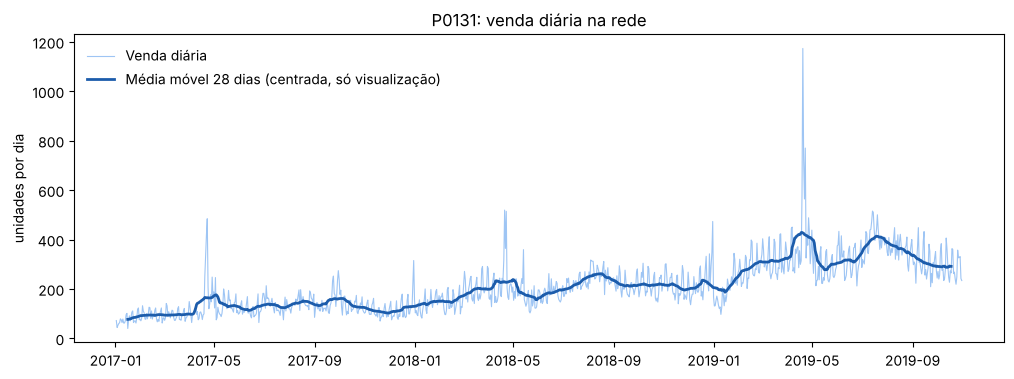

In [2]:
# Série diária do P0131 (grão produto x dia, base demanda.csv)
dados_p0131 = pp.carregar_dados("dados/demanda.csv", "P0131")
venda = dados_p0131["unidades"]
print("Dias:", len(venda), "| vazios:", venda.isna().sum(), "| dias com venda zero:", (venda == 0).sum())
print("Venda média/dia:", round(venda.mean(), 2), "| preço médio: R$", round(dados_p0131["preco_medio"].mean(), 4))

fig, eixo = plt.subplots()
eixo.plot(venda, color="#9ec5f4", lw=0.8, label="Venda diária")
eixo.plot(venda.rolling(28, center=True).mean(), color="#1c5cab", lw=2, label="Média móvel 28 dias (centrada, só visualização)")
eixo.set_title("P0131: venda diária na rede"); eixo.set_ylabel("unidades por dia"); eixo.legend(frameon=False)
plt.show()

Seg    0.919
Ter    0.889
Qua    0.880
Qui    0.910
Sex    0.986
Sáb    1.218
Dom    1.201

Força da tendência: 0.817 | força da sazonalidade semanal: 0.370


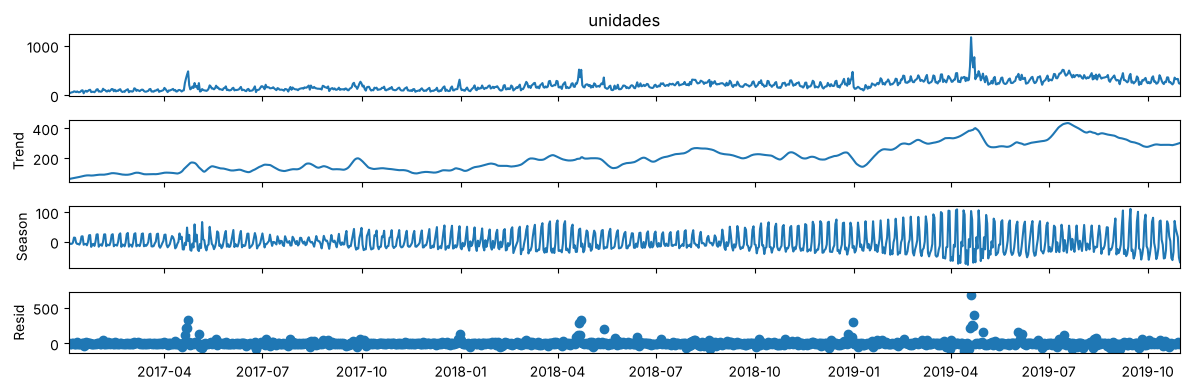

In [3]:
# Ciclo semanal
nomes_dias = ["Seg", "Ter", "Qua", "Qui", "Sex", "Sáb", "Dom"]
media_por_dia = venda.groupby(venda.index.dayofweek).mean()
media_por_dia.index = nomes_dias
print((media_por_dia / venda.mean()).round(3).rename("índice vs média").to_string())

# Decomposição STL robusta (período 7) e forças de Hyndman
stl = STL(venda, period=7, robust=True).fit()
forca_tendencia = max(0, 1 - stl.resid.var() / (stl.resid + stl.trend).var())
forca_sazonal = max(0, 1 - stl.resid.var() / (stl.resid + stl.seasonal).var())
print(f"\nForça da tendência: {forca_tendencia:.3f} | força da sazonalidade semanal: {forca_sazonal:.3f}")
stl.plot(); plt.show()

In [4]:
# Triagem de produtos em descontinuação: média dos últimos 90 dias / média de 445 a 90 dias atrás
data_final = demanda["data"].max()
recente = demanda[demanda["data"] > data_final - pd.Timedelta(days=90)]
anterior = demanda[(demanda["data"] > data_final - pd.Timedelta(days=445)) & (demanda["data"] <= data_final - pd.Timedelta(days=90))]
triagem = (recente.groupby("produto")["unidades"].mean() / anterior.groupby("produto")["unidades"].mean()).sort_values()
print(triagem.head(6).round(3).to_string())
print("Razão < 0,6 (descontinuados):", list(triagem.index[triagem < 0.6]))

produto
P0438    0.000
P0051    0.108
P0079    0.138
P0590    0.806
P0035    0.826
P0185    0.834
Razão < 0,6 (descontinuados): ['P0438', 'P0051', 'P0079']


In [5]:
# Efeito da promoção (pct_lojas_promo)
promo = dados_p0131["pct_lojas_promo"]
forte, fraca = promo > 0.2, promo <= 0.02
print("Multiplicador bruto (promo > 20% vs <= 2%):", round(venda[forte].mean() / venda[fraca].mean(), 2))
base_local = venda.where(fraca).rolling(28, min_periods=10).median().shift(1)
print("Multiplicador vs base local (mediana dos 28 dias anteriores sem promo):", round((venda / base_local)[forte].median(), 2))

Multiplicador bruto (promo > 20% vs <= 2%): 1.48
Multiplicador vs base local (mediana dos 28 dias anteriores sem promo): 1.28


**Decisões da Fase 2:** grão produto x dia (`demanda.csv`); a série tem tendência e sazonalidade semanal (período 7);
a promoção entra como variável externa; P0438, P0051 e P0079 saem do painel; venda ≠ demanda (dias de ruptura parecem apagados), registrado como limitação.

## Fase 3: Preparação dos dados
Regras: separação **apenas temporal** (teste = últimos 28 dias), sem embaralhar; nenhuma informação com menos de 28 dias de antecedência.

In [6]:
painel = demanda[~demanda["produto"].isin(["P0438", "P0051", "P0079"])]
print("Painel:", painel["produto"].nunique(), "produtos,", len(painel), "linhas")

H = pp.H
data_corte = dados_p0131.index.max() - pd.Timedelta(days=H)
treino = dados_p0131.loc[:data_corte]
teste = dados_p0131.loc[data_corte + pd.Timedelta(days=1):]
real_teste = teste["unidades"]
print("Treino:", treino.index.min().date(), "a", treino.index.max().date(), f"({len(treino)} dias)")
print("Teste: ", teste.index.min().date(), "a", teste.index.max().date(), f"({len(teste)} dias) | total vendido: {real_teste.sum():,.0f}")
print("Dias de promoção no teste:", (teste["pct_lojas_promo"] > 0).sum())

Painel: 27 produtos, 27883 linhas
Treino: 2017-01-02 a 2019-10-03 (1005 dias)
Teste:  2019-10-04 a 2019-10-31 (28 dias) | total vendido: 8,158
Dias de promoção no teste: 0


## Fase 4: Modelagem (janela de teste única)

In [7]:
def wmape(real, previsto):
    return np.abs(real - previsto).sum() / real.sum() * 100

def vies(real, previsto):
    return (previsto - real).sum() / real.sum() * 100

previsoes = {}
previsoes["Naive sazonal"] = pd.Series(np.tile(treino["unidades"].iloc[-7:].values, H // 7), index=real_teste.index)
previsoes["Média 4 semanas (atual)"] = pd.Series(treino["unidades"].iloc[-28:].mean(), index=real_teste.index)
with warnings.catch_warnings():
    warnings.simplefilter("ignore")
    ajuste_hw = ExponentialSmoothing(treino["unidades"], trend="add", seasonal="add", seasonal_periods=7,
                                     initialization_method="estimated").fit()
    previsoes["Holt-Winters"] = pd.Series(ajuste_hw.forecast(H).values, index=real_teste.index)
    ajuste_sarima = SARIMAX(treino["unidades"], order=(2, 1, 2), seasonal_order=(1, 1, 1, 7)).fit(disp=False)
    previsoes["SARIMA"] = pd.Series(ajuste_sarima.forecast(H).values, index=real_teste.index)
previsoes["SARIMAX + promo"], convergiu = pp.prever_sarimax(treino["unidades"], treino[["pct_lojas_promo"]], teste[["pct_lojas_promo"]])

placar = pd.DataFrame({nome: {"WMAPE %": wmape(real_teste, p.clip(lower=0)), "Viés %": vies(real_teste, p.clip(lower=0))}
                       for nome, p in previsoes.items()}).T.sort_values("WMAPE %")
print(placar.round(2).to_string())
print("\nSARIMAX convergiu:", convergiu, "(configuração padrão, a mesma usada no backtest)")

                         WMAPE %  Viés %
SARIMAX + promo             8.49    1.34
Holt-Winters                9.30   -3.82
Naive sazonal              10.17   -1.84
SARIMA                     10.22    1.63
Média 4 semanas (atual)    17.18    3.79

SARIMAX convergiu: False (configuração padrão, a mesma usada no backtest)


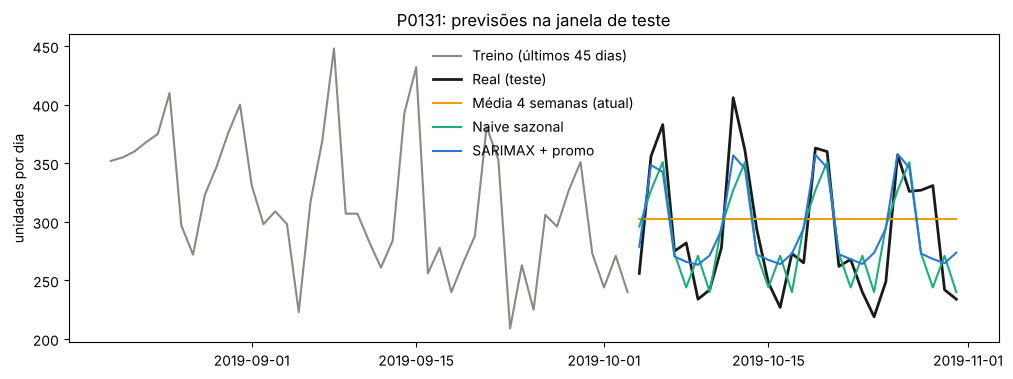

In [8]:
fig, eixo = plt.subplots()
eixo.plot(treino["unidades"].iloc[-45:], color="#8a8984", label="Treino (últimos 45 dias)")
eixo.plot(real_teste, color="#1a1a19", lw=2, label="Real (teste)")
for nome, cor in [("Média 4 semanas (atual)", "#eda100"), ("Naive sazonal", "#1baf7a"), ("SARIMAX + promo", "#2a78d6")]:
    eixo.plot(previsoes[nome], color=cor, label=nome)
eixo.set_title("P0131: previsões na janela de teste"); eixo.set_ylabel("unidades por dia"); eixo.legend(frameon=False)
plt.show()

## Fase 5: Avaliação
Backtest com 12 origens a cada 14 dias, horizonte de 28 dias, os mesmos 5 modelos (leva cerca de 1 minuto).

In [9]:
venda_total, promo_total = dados_p0131["unidades"], dados_p0131[["pct_lojas_promo"]]

def prever_todos(tr, promo_tr, promo_fut):
    saidas = {"Naive sazonal": np.tile(tr.iloc[-7:].values, H // 7), "Média 4 semanas": np.repeat(tr.iloc[-28:].mean(), H)}
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        saidas["Holt-Winters"] = ExponentialSmoothing(tr, trend="add", seasonal="add", seasonal_periods=7,
                                                      initialization_method="estimated").fit().forecast(H).values
        saidas["SARIMA"] = SARIMAX(tr, order=(2, 1, 2), seasonal_order=(1, 1, 1, 7)).fit(disp=False).forecast(H).values
    saidas["SARIMAX + promo"] = pp.prever_sarimax(tr, promo_tr, promo_fut)[0].values
    return saidas

linhas = []
for origem in pp.origens_backtest(dados_p0131):
    tr = venda_total.loc[:origem]
    futuro = venda_total.loc[origem + pd.Timedelta(days=1):].iloc[:H]
    for nome, prev in prever_todos(tr, promo_total.loc[tr.index], promo_total.loc[futuro.index]).items():
        prev = np.clip(prev, 0, None)
        linhas.append({"origem": origem.date(), "modelo": nome, "wmape": wmape(futuro, prev),
                       "erro_total_un": futuro.sum() - prev.sum(), "total_previsto": prev.sum(), "total_real": futuro.sum()})
backtest = pd.DataFrame(linhas)

resumo = backtest.groupby("modelo").agg(wmape_medio=("wmape", "mean"), wmape_desvio=("wmape", "std"),
                                        previsto=("total_previsto", "sum"), real=("total_real", "sum"))
resumo["vies_global %"] = (resumo["previsto"] - resumo["real"]) / resumo["real"] * 100
indice_pior = backtest.groupby("modelo")["wmape"].idxmax()          # pior janela de cada modelo
resumo["pior_wmape"] = backtest.loc[indice_pior].set_index("modelo")["wmape"]
resumo["wmape_sem_pior"] = backtest.drop(indice_pior.values).groupby("modelo")["wmape"].mean()
print(resumo.drop(columns=["previsto", "real"]).sort_values("wmape_medio").round(2).to_string())

                 wmape_medio  wmape_desvio  vies_global %  pior_wmape  wmape_sem_pior
modelo                                                                               
Holt-Winters           15.36          9.80           1.84       43.29           12.83
SARIMAX + promo        15.70         13.51           6.93       56.83           11.96
Naive sazonal          16.15          8.34           0.58       39.96           13.98
SARIMA                 17.98         16.48           6.57       68.98           13.35
Média 4 semanas        22.05         11.56           6.12       54.57           19.09


In [10]:
# Nível de serviço ótimo e simulação de custo (critério 3)
preco = dados_p0131["preco_medio"].mean()
cu, co = pp.MARGEM_PERDIDA * preco, pp.CARREGO * preco
print(f"Preço médio R$ {preco:.4f} | Cu R$ {cu:.4f} | Co R$ {co:.4f} | Cu/Co = {cu / co:.0f} | nível de serviço = {cu / (cu + co):.4f}")

def simular(erros, nivel_servico, usar_es=True):
    erros = np.asarray(erros, dtype=float)
    es = pp.estoque_seguranca(erros, nivel_servico) if usar_es else 0.0
    falta, sobra = np.clip(erros - es, 0, None), np.clip(es - erros, 0, None)
    custo = falta * cu + sobra * co
    return {"estoque_seguranca": es, "custo_medio_periodo": custo.mean(), "falta_media_un": falta.mean(),
            "origens_com_falta": int((falta > 0).sum())}

erros_por_modelo = {m: g["erro_total_un"].to_numpy() for m, g in backtest.groupby("modelo")}
simulacao = pd.DataFrame({m: simular(erros_por_modelo[m], pp.NIVEL_SERVICO)
                          for m in ["SARIMAX + promo", "Holt-Winters", "Média 4 semanas"]}).T.sort_values("custo_medio_periodo")
print(simulacao.round(2).to_string())
hoje = simular(erros_por_modelo["Média 4 semanas"], pp.NIVEL_SERVICO, usar_es=False)
print("\nProcesso atual sem estoque de segurança:", {k: round(v, 2) for k, v in hoje.items()})
economia = simulacao.loc["Média 4 semanas", "custo_medio_periodo"] - simulacao.loc["SARIMAX + promo", "custo_medio_periodo"]
print(f"Economia do SARIMAX vs processo atual: R$ {economia:.2f} por período | R$ {economia * 13:.2f} por ano (13 períodos)")

Preço médio R$ 2.5870 | Cu R$ 0.7761 | Co R$ 0.0517 | Cu/Co = 15 | nível de serviço = 0.9375
                 estoque_seguranca  custo_medio_periodo  falta_media_un  origens_com_falta
SARIMAX + promo             779.06                91.21           21.37                1.0
Média 4 semanas            2112.92               147.09           10.17                1.0
Holt-Winters               1498.56               159.99           88.96                1.0

Processo atual sem estoque de segurança: {'estoque_seguranca': 0.0, 'custo_medio_periodo': np.float64(459.69), 'falta_media_un': np.float64(519.83), 'origens_com_falta': 4}
Economia do SARIMAX vs processo atual: R$ 55.88 por período | R$ 726.43 por ano (13 períodos)


**Resultado da Fase 5:** o SARIMAX + promo é o único que passa nos três critérios no P0131.
Ressalvas: estoque de segurança e custo são calculados nas mesmas 12 janelas (otimista); períodos tratados como independentes; venda ≠ demanda.

## Fase 6: Implantação (política de pedido)
**Pedido = demanda prevista (28 dias) + estoque de segurança − estoque disponível no CD.**
O estoque do CD não está na base (`estoque_total` é a soma das lojas); usamos 3.000 unidades como premissa.

In [11]:
erros_sarimax = backtest.loc[backtest["modelo"] == "SARIMAX + promo", "erro_total_un"]
conta = pp.politica_pedido(previsoes["SARIMAX + promo"].sum(), erros_sarimax, pp.ESTOQUE_CD_PADRAO)
vendido = real_teste.sum()
print(f"  Demanda prevista (28 dias)     {conta['demanda_prevista']:>10,.1f}")
print(f"+ Estoque de segurança (93,8%)   {conta['estoque_seguranca']:>10,.1f}")
print(f"= Necessidade bruta              {conta['necessidade_bruta']:>10,.1f}")
print(f"- Estoque disponível no CD       {conta['estoque_cd']:>10,.1f}")
print(f"= PEDIDO                         {conta['pedido']:>10,.1f}")
print(f"\nVendido nos 28 dias de teste     {vendido:>10,.1f}")
print(f"Sobra (+) / falta (-)            {conta['estoque_cd'] + conta['pedido'] - vendido:>+10,.1f}")

  Demanda prevista (28 dias)        8,267.0
+ Estoque de segurança (93,8%)        779.1
= Necessidade bruta                 9,046.1
- Estoque disponível no CD          3,000.0
= PEDIDO                            6,046.1

Vendido nos 28 dias de teste        8,158.0
Sobra (+) / falta (-)                +888.1


### Como o pedido é entregue
- **CSV (lote):** `python gerar_pedido.py --estoque-cd 3000` grava `saidas/pedido_P0131.csv` (componentes do pedido),
  `saidas/previsao_diaria_P0131.csv` e `saidas/erros_backtest_P0131.csv`.
- **App:** `streamlit run app.py` lê esses CSVs; o comprador muda o estoque do CD e o nível de serviço e vê a conta aberta.

**Limitações:** resultado validado só no P0131; venda ≠ demanda (rupturas apagadas da base); estoque do CD é premissa;
o SARIMAX com ajuste padrão não converge e é sensível ao otimizador.